# Exploratory Data Analysis (EDA) — Simple Hands-on
**Dataset:** drinks.csv  
**Goal:** Understand global alcohol consumption using simple, essential pandas methods and basic visualizations.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (works whether notebook is run inside Day10/O2_eda or workspace root)
data_path = '../assets/drinks.csv' if os.path.exists('../assets/drinks.csv') else 'Day10/assets/drinks.csv'
df = pd.read_csv(data_path)
df.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa


### 1. Basic Dataset Information
Check dimensions (rows & columns), data types, and null values.

In [2]:
print('Dimensions (rows, cols):', df.shape)
df.info()

Dimensions (rows, cols): (193, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 6 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   country                       193 non-null    object 
 1   beer_servings                 193 non-null    int64  
 2   spirit_servings               193 non-null    int64  
 3   wine_servings                 193 non-null    int64  
 4   total_litres_of_pure_alcohol  193 non-null    float64
 5   continent                     193 non-null    object 
dtypes: float64(1), int64(3), object(2)
memory usage: 9.2+ KB


In [3]:
# Check for missing values
df.isnull().sum()

country                         0
beer_servings                   0
spirit_servings                 0
wine_servings                   0
total_litres_of_pure_alcohol    0
continent                       0
dtype: int64

### 2. Summary Statistics
Basic descriptive statistics (count, mean, std, min, 25%, 50%, 75%, max).

In [4]:
df.describe()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
count,193.000000,193.000000,193.000000,193.000000
mean,106.160622,80.994819,49.450777,4.717098
std,101.143103,88.284312,79.697598,3.773298
min,0.000000,0.000000,0.000000,0.000000
25%,20.000000,4.000000,1.000000,1.300000
50%,76.000000,56.000000,8.000000,4.200000
75%,188.000000,128.000000,59.000000,7.200000
max,376.000000,438.000000,370.000000,14.400000


### 3. Continent-Wise Analysis
Which continent drinks the most on average?

In [5]:
# Average servings per continent
df.groupby('continent')[['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']].mean()

,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol
continent,,,,
Africa,61.471698,16.339623,16.264151,3.007547
Asia,37.045455,60.840909,9.068182,2.170455
Europe,193.777778,132.555556,142.222222,8.617778
North America,145.434783,165.739130,24.521739,5.995652
Oceania,89.687500,58.437500,35.625000,3.381250
South America,175.083333,114.750000,62.416667,6.308333


### 4. Simple Visualizations

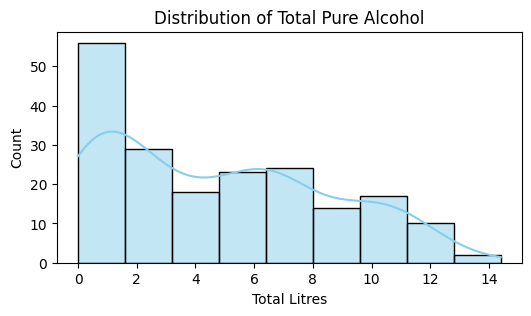

In [6]:
# 1. Distribution of Total Alcohol
plt.figure(figsize=(6, 3))
sns.histplot(df['total_litres_of_pure_alcohol'], kde=True, color='skyblue')
plt.title('Distribution of Total Pure Alcohol')
plt.xlabel('Total Litres')
plt.show()

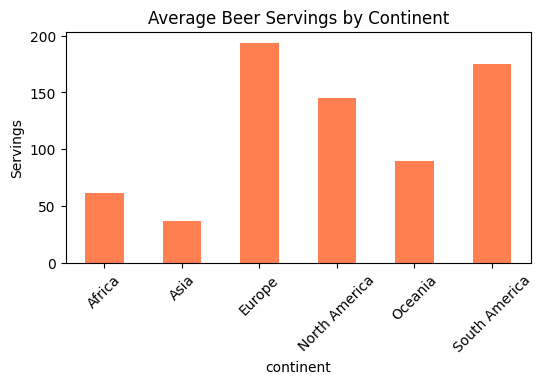

In [7]:
# 2. Average Beer Servings by Continent (Bar Plot)
plt.figure(figsize=(6, 3))
df.groupby('continent')['beer_servings'].mean().plot(kind='bar', color='coral')
plt.title('Average Beer Servings by Continent')
plt.ylabel('Servings')
plt.xticks(rotation=45)
plt.show()

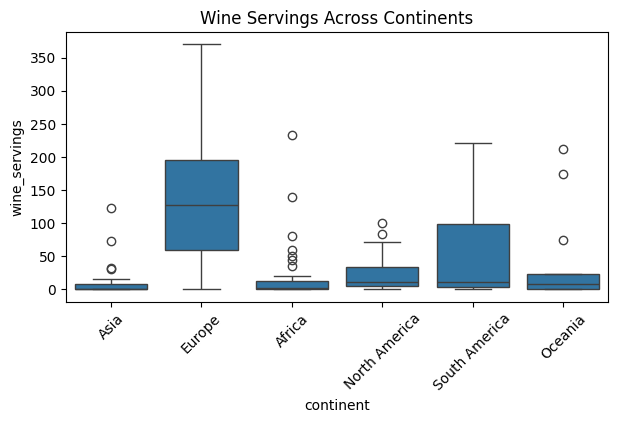

In [8]:
# 3. Wine Servings Distribution by Continent (Boxplot)
plt.figure(figsize=(7, 3.5))
sns.boxplot(x='continent', y='wine_servings', data=df)
plt.title('Wine Servings Across Continents')
plt.xticks(rotation=45)
plt.show()

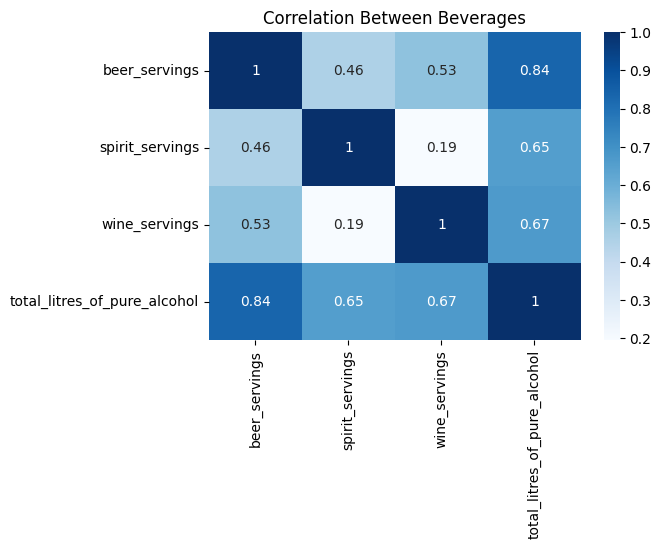

In [9]:
# 4. Correlation Heatmap
plt.figure(figsize=(6, 4))
num_cols = ['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues')
plt.title('Correlation Between Beverages')
plt.show()

### 5. Simple Key Findings
1. **Europe** has the highest average consumption in beer, wine, and total pure alcohol.
2. **Beer** has the highest correlation ( = 0.84$) with total alcohol consumption.
3. **Wine** consumption is heavily concentrated in European countries, with notable outliers like France and Portugal.